# PetFinder: EDA, baseline и проверка гипотез

Ноут для ДЗ1. Для каггла: **Kaggle -> New Notebook -> File -> Import Notebook**, подключите данные конкурса **PetFinder.my Adoption Prediction**
через Add Input после принятия правил конкурса и выполните Run All. CPU достаточно.

Внутри сохранен `src/` и конфиги репозитория.
Выходные файлы появятся в `/kaggle/working/petfinder_outputs`.

## Задача и гипотезы до эксперимента

Один объект — объявление, иногда сразу о нескольких животных. `y=AdoptionSpeed`
принимает значения 0-4, от пристройства в день публикации до отсутствия пристройства после 100 дней. Интервалы не равны числу дней. `X`: структурированные атрибуты и, в отдельном эксперименте, `Description`.

Основная гипотеза: TF-IDF описания дополнит таблицу и даст **deltaQWK >= 0.02**
относительно той же Logistic Regression без текста на одинаковых групповых фолдах.

CatBoost проверит нелинейные взаимодействия; регрессия против классификации —
пользу учета порядка категорий. Подробный план и критерии — `docs/experiments.md`.

Метрика: QWK; дополнительно macro-F1, MAE, recall редкого класса и ошибки >=2 категорий.

In [1]:
import base64, hashlib, io, json, os, sys, zipfile
from pathlib import Path

WORK_DIR = Path(os.environ.get("PETFINDER_OUTPUT_ROOT",
                 "/kaggle/working/petfinder_outputs" if Path("/kaggle/working").exists()
                 else "outputs/kaggle" )).resolve()
WORK_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(WORK_DIR / ".matplotlib"))
SOURCE_DIR = WORK_DIR / "backbone"
SOURCE_DIR.mkdir(exist_ok=True)
payload = base64.b64decode('UEsDBBQAAAAIAAAAIVwsH2TZbwAAAIYAAAAVAAAAY29uZmlncy9iYXNlbGluZS55YW1sJYxBCsMwDATveoUeUIJbmouvfUYpRsGqMdiVkWVofl8nvc2ys9uZo8f7DXor2Tx2U7L8zhxDUhkNPuFsuscVqkQuk55x1LpfsEhSTsFoG4X0BZuIHQctKDemc+Qc/DUPiA+P18VNqPQN2VhnPowfUEsDBBQAAAAIAAAAIVx70ifdywAAADgBAAAYAAAAY29uZmlncy9leHBlcmltZW50cy55YW1sTZDRjgIhDEXf+Yp+gDE46j701c/YbAgOnZGEAVJKon9vUTe7PN2e2/YCjSggnCbTaoqC0IS9xCVScCuXXk12L6chnM1WAiVV36Fv22MHqaxMqxN/7cnzX0132cHs5VpKE6eIqbXC/9icfGsjhn+MEhmxVTsr+VeUtea9DA3ABeGwtyo2f3dRiLUeHSMHP3jRwa4xCJPVY36Thj9G9FElq3uyY1GgKjeEL5WJPOeYV6cthGD39jzo5NRYxt0RjgrkxuSDm0vP+kuTeQJQSwMEFAAAAAgAAAAhXMBQDOuqAAAA6wAAACIAAABjb25maWdzL3N0cmF0aWZpZWRfZGlhZ25vc3RpYy55YW1sNY7LisMwDEX3+ooLsy3BU9qNt+1fDENQE9kYHDvICrTz9eP0odU9Fx2hL1wTx1KbpQm15IcHY04hiEoxRCminNMfW6oFxhrFELQu2EoTKVBp0ybaBuo4e5yO1NaczKOZdiskmamMz655nGmps+SefnKNKnE0vm2Z9YAPy91+6Var7QfWUWUV3lVHrw1PwMXje3A9LHwfk4l2PjtHu+zfdeja1t/zOLo+9A9QSwMEFAAAAAgAAAAhXONXusaeAAAAwQAAABAAAAByZXF1aXJlbWVudHMudHh0RY07DsIwEER7n8ISNSvshIiPtqAHKaKjdJxFGOJ15BikdNyBG3ISTCgoZ+bNzEwe6UyR2JIkfrgY2BOnjazHdAksC1i/n68ClN7+LaVkJBt8JltqQfDd9yOiAl1BKXrDrRkQNWgoxGDdL1O591U3l+YdmchfcwlaWJOaEIY0DcBKeJP6LqTONYj5Pi/W42l32CNWsMj8NTRTpqDM6gNQSwMEFAAAAAgAAAAhXNHbkpQ+AAAAPgAAAA8AAABzcmMvX19pbml0X18ucHlTUlK6MPfC1gu7Luy72ATEDRc2XOxXuLDxwoYL2y9sULjYe2HXxcYL+y9sBcrsuLAHqHIvSN2FTXpKSkpcAFBLAwQUAAAACAAAACFcaITiuDkGAAAxDgAACwAAAHNyYy9kYXRhLnB5lVdbb9RGFH7fXzGdh8puFucC7UNQhLa5UCQIkARe0tVqsp7sWnhtd+wlpFEkIOpFKqIvPPam9g8kQNoQSPoXvP+o35kZr+2QpnSV7I5n5ty+78yZY855/kt+kP+Vn44ej77Lj/Jjlr/O9/OT/GT0w+gbznljU8UDloisHwYbLBgkscrYHTw27LgvUlpqFM/RcJBsM5GyKCmmEhH5mMBf4jcaa62V64trbI7xlh8nWRBHq4mUPm/M32ytri6uYmV9qsmmm2ymyS432ZV2Y/nercWVG/O0wls9yZuM3x2KKAuybRovST11P/Bl3BpkNL7TjzM9bjfmW2uL129DvHWTFDQYPnxtO9EynyuYnh6PZmh0XUa+VDSaj8NYTY9HM+PRZd40em6JbKjgxmrwtda3NFQ3ZdTL+toh0e0GkcgQHJ4W5FasBma8mkkVhJDxC0VfSBEaqdUMEphuN1YW7967sbK4oOO+I7MbC7S+ItPuUCrzsCwG0ihPuyrQaPI2m2AFYhOsEn6j0fDlJtsMIr/TTR86Ko6zJh5DGUGNO2s8QU78hhT4C0mwP/qR5W/z0/wYw2/zI3qspAfTGiYzJYLIg0KGBHqbH7FytlxzPUomMkCriIhySMu7ejZNwoCmuZbgLNgcO8bmimlSxJkMU4kJmWZGYRfpFfgALSWgtPrJsXCT2QljoFxoa9nNeBj5JJZgqFjCgqiqD14kXpB2SMhxjQjmoMHRki77aI5NG+B0bCKAb0vYvRxnS7RjUalYOeMN2iYduj+BFaAcPWc7hUe7V1n+9+gxYP6eQMcCKdj1WP4rZk9HT/J3+H6K8SEYOGX5S7ZT+op9vGaG5z/lBww7D6EWHL7Oj0fPccgPibwKj1gfPWFEcf4KdvcLFkly9JSsQL+YVGJrsjRgSFMS2R8ZENen2ja//CDtxg+l6hDyTiqF6vb1eI5PPhC9XigngygZZtxmXI2/FAVD+s5O4iVCySizP4YJO1VPCpsQxWoNg9pnTLBOvYpfrqd6YbzhVJLM3XWrZJcufijjIPnn0R5o1kwRradg4Qgk7oPCZ2yhtdbqrNy+vXaVqAC5mN3DDk3IbI1YXgO7XCgRfyhCPdXZVIDG0d9NpqOZW1PD4mgPgjQNoh6hLDNnXF0mmLNuinKb4tViBtP1tuuyS3q31ul143A4iNIxNlbjWTjui3AoSxxMHh0DAaolJxgdIULLtFXhFmHSwde25CDJti/QzHEs9gg36Hyj8xnDfQAMa1YXMf5AbhPn5xbQdqm+MLuO/W0c+Ug4rieibcdlUFJZEmmGu8NJM+V6+KL/IMFe+ZXDuRWZrSXhhZi81Wdyn+1A+XsQaJc9f4jS1aVrxHlP/zmovEAeHdAJ1mi/1Mf8CIfcxD+2YGhGMjHDbZEC78UeoXye3RFEjr2tsTEMHfdCl2r3vKk0lAxvLhF3YA69xx5qD2auMUKGTV26UmEQSUcMnnullWbRd+BO7SK5E9/L4o59tsFBR7vJJPmTzvFuLFVXWhMaj0gfIQiX2z0ETkiwjwvdFppqzljB/0E7oz4LWUqVdgd2dnlNYZRoeDedwqav4oSsfnBq/QHVSC7UeV3FXzJkwyEMHuuzdwjzJ7bePDvPAYt2tWuiJDnrjjeIfWfa9SLpTH2way90CaCaiFvmAC0E+aCbC3L3FXWh1GQ0Ga2fVLE6nR37akpeGAu/QxeT7WK2gqzfoZ6gWvBMjuuMUFKYpudM91Ot+QaHM8VUr5sVUg9ty3Eki1M0NlsGb3ddaBNbqibPM4stRQlfEijGNZJsD43g6rb/pST8TglA9QZ9gO4A3o32zOED4NTqvdN5gc7gWj0ZqPIbgHT1oLOgp8h/M/NftvUuZuwT2TojbRPzhjhujufMpvywft9p800d57h/DWUn7YuZTz9z6MXE+uAHPYO8fSPx7BajjYhicYK7nETAgdrgLr2SoH5LMSjD0BWnP4weELoB+nQnFIMNX8zanZpVZ3pq5gr7hNGP22QbnJ8BwjjjDROi1NH6alHZ9b58ZEZOkdcR3hGEfjPo+GVPb6qYtVF0XfqKqDT+HoAJcTb1NXTmlgrjLURixkomoejKsilV/Mt0gm5Ghi8le/KRPkR6vXbJNf4BUEsDBBQAAAAIAAAAIVx/enEfewsAAOggAAAKAAAAc3JjL2VkYS5weZVZzXLcxhG+71NM4ZACYhBamnYSs7IHlkTLqpIlhaR9WW9Qw8XsEhL+jBmQS7Po8iE5pfIKySsojl3On/UMyzdKd88MdrDAUvSqtFzMT09Pd8/3dQ88z1v//e679bv19+sf4e9/1m/Z+of12/XP65/v/nL3Z8/zRmlelbVivF5WvJbCPr+WZTFa1GXOKq4usvScmY5X8Diyo3KuqqxU0D3a/IwaKXzvaLn0gv64qLrGX4xLVmXK9hdNXl1jW1HZpooXCTTguGSkNYkSrrjV4/HR2fHTlyfPHh89D9nj50enp8enIXvxxefH0Bayk+M/fPHs5PhJyM6OTp4en4VskRZJPJeXISvKOudZ+o1I4kTIeZ1WKrW7jcQlzxquhF1H8ksRkzVGj18+OY5Pjl48PT5lE3bjnV1Xwjtk0/2QfTgLmfdUFImobUvIDmbhiHU/3udcNXWqrk9heRw5DpkZHLKPUMinTf1cFEt10e0dEPWZ4Fl/GPO+5PN5WsAWkvtVeSKuwBBbo5h3qkSdknXcjtvRaJSIBVvUPBcxb5JU+fQ7ZBk/F5lIgkNaIU+lTItlPC+zJi8kGEqCGUXiS6F86xX2AfOn2jEzli6sCCYyKdh0FgRsj+F4WiEISLDjKhA67EMzAUXC9tpmj6WF1lyvUCXRKWxSSD9R4MOJVLVeoygLkVfqGhZwpE6d31EBse0FMxpeC9lkCmOhNa4nLzhFRZZKo39ETQGYdss2MGqrZeMkr2iyDJqbQuG4GxhwCLtQPjUFbFHWDNpCRs/t/qJUFtwPItnk8J0qkUs/uHXE0vZi2LBetSeepEzhcRYt0iwDYbDbiEu0k492iuAL/6cVLCC+pm5aLdgOsN7H6IzKTr0XsI4Xdt1EsWBGkCKu5klTZekcwjquyytUulU3arsSu/VgcGIlVJwm3bmvhHr2ZEgCBRH1bofPC4gSR34tKoEzYxs9bkTaxWzfe3QdFBFfpeoCpcdcztN0WyI6ZF4WiqeF9Gtv+sevVuPx3ler3y5mYOBaLMVqclY3YmC5tAC0SwEWy0Q40dDxZBsabmwUpcI4Y79i3zqtKcSyTxKDwaBog5bGoFUdSLXRuh0DrQQ3GAqx5CoFZAbmgJM8HwplH465Ku0IR/uQibouaznx5qWo58IL2O/Z+MFhvBXKhnLuC110XV/RX2Llh2/FIMB99ne1/sAl0geZXoqcFwp20hRvivKqeO+OnA0BXmCo3R8cOAJVuNkmy/EWPeJzS4LjHsFtfbq8eBB2CPBgm/gObh8aj7f0jWBxAme2EbULGIftaG0l4AoNO+3YCPMNe/j8jUk0t0wBXWhgvKzLppIAkZh5FGD89OuGeEYUmhMkMkwGeZyQSo/2HMaQUc5XBtWcKRrQ3ms763ogjUwoiGajTWcBcO5+H2PuFWjorwPIG8u4XBa0Zra5AuSHJrcbsLa13jzjUtoIJdsBWvpvAr3gpebRNwBIrQyblmz5JcIsJoYUUqwcYt2xXlWXmDsS/M866QF+rAaLrOS/RIc25bFo/iCNLMQrjAylZZFSBDbfdtcjADfJdB9CrMg+NwH9LIDVFCYV5B/ZLtE94+RhMFG6LPzhFG7i/A6irJzvzL7sJ6JgPL/2vWGJXtDur9DHBuy1VJtgNbkcYE1h9miS3bxMQBywMRhRFKqsr/26LFXITOYrgcqVyXuhllr/bf2P9U/rd3ffsbs/QZX17/V/129DKqWYDzXXOwb9P65/Ynd/Xf+Pfv4A//4FPf9cfx9gMUaKwApgO6yzaDWrnk01tYsxZqx6oEizWKQrSqx8L805YADmVtHrCoqwkPleLhTH6km3SjQKNkvYVZrDl9M+czALzlgK0wTi1pQUe8QW3g3t+za+sQrcYp6he6kL/tqujasWZQbVEabuYoXkTFuoUGdnGTjfFURhnKQ1ogilWpsAhF4jJZXUddgJBBOf7dIElfySpxCSGWLlpxzQLkQK4/X8Qhc4eBqrYEiZ2e0Wn4GtimaD/1gYO/WN1iyql1l57i+8X99op9x6zgmC5BMtiTMhbRM57siqyyYT5jjEVCp2ZFSTZX1vD2y9H0zHM60y9KPWpMusTzabSgeWDtmm3NlFO/PyUtQQPy1R6fzYLQByXln6sDXCeCNA5wR6o20J15fi2KRYlD1PIcKBo7RN4Rm9pB+Q5WBVIQ330c4H+MbDKkGjkx2uuUrvDwGgTflCZ3TZqOEJQG/j3fSmdYrBJ21e1K02cCLZXMO9uKYsuKFMxxCowfAHUWf/A6EEUqGEpWqwdUPgcMJ2tBmkICr1Xl2UqjzK1VDyYv00daxa4XgdQDHweM7V/KJF/dZqANgmAoz4HquAUga+UCUNQt2VFxAXDRzuEDdIBwjyXoytfgLZOQ/Tw/3xeHbYs6eqr/uN+CnPX4N01ACIhyeSgiuqBQf6RNASBeSmwHETr1GLvd95O4oF2BESqVS8mAsfhMLBA3IMhhfFD+4raiqEHRwf4fOuUgRxYbcka6uIV5UoEr2DAi9FelPEai4qxfyXp8dYQ4TsS4xH+r1D1QcKx0ixu0Fj6vMUS55XkLhNcsgxwDGhc3zvyRf1rJguJ2OrwGQTEkZqrMoqzsSlyGI03sSAMv7uZzAuQ6CyOxOAuilikXBf1VBchwxIAcgfEKJqlGa8CRGUtpZut9StnwKnJ8rfIK3BTgDf5URDnFilkK6Xb3ROZxShi0eERFoXAMS9dTO60Hh9tCVwWc412j8Bkv8UR/s3nr5Uguk0JbJ3TMwjGmjb6Ul2IJ6QSd6bxDu5uxbTuXl6iIC2hNHzbW6WQPJc8AlxtRV0GzgbxUp4Li+NhSHX8Ew7NAI5UkZsptOsllds/YwIghXdvUU8KaUZlX5Oe2JmkU4yz4VfYe0NzA1hPpmOo/F+yMbRx/j1ySezoK+wvQwAY+W8vibNA1vgYJRhgoNI3k1ydGRMPRxBUNuJCwpOZ9+dGbiFuJ3XLUg8BOsMzjSm7xvWwuOJKKvdQwyOVxHUBIJMy9bRJd3iDUvohU0Ra6iQZrtlHgCCXqRtHCbaYeFuqm+vxgYvh3F2oJfrBSbuatc0XIWupG8873aHZk0hhShivNhbQp2glbQm374awc/mwgeH9G7VNo0b8+hnfT5Ag50XVk5cD1/uUIQh6bux7tzxtLU2JfX3hyK5wAAq5JkUXjvrJoNdBtc6OcDuqN+O/IevRidCnxYDIPZljq8FWjDHM0mnyNRAdv+b+wXSeOA2Rztmx51BLXR53r6ewnQ5pkETJ2XuwTaW6IdmDUx3az430W3WfUSHUwfmLa5TEA4Al/halRZzOlbcbNa9F3HQh6InXYaMr5BOMgUhdo7v66QPzRLvHvzfhOwgCLYsEeGg6JzXPl9N+ArJUblb5KsIT9iKLgcm3lFS0tk6rQRUYSG7Nu3PgQwBhLB4VanKxMQ7o2sLyJ/wlcN5Q29/zMa7OkcqXV6oOOPXsEu/24Vuh7/+9v5dqVEFXAaJWpVO9j9ynQNGmGelFGgB3WwsRFVxx0b7OqfpMUWAnjfm2/8Y7Qd5C3CdgAYHsPHcou3MqfwmrXxcBWq9sE9iToqmOVLzv3NLvMGMgVtiiyKuhy7wlVVRQe673K90sQLBkYEaWXklavAn6H0Oie3koOfamPwFda+ejLfwt9ZDO7wz7BlLja5v5JBzBhzTpnB4tu0dDhjBN8aiJBKvIOzb7uioXjZYbr+iHqOYHhbxJIm56Ye6ew/vT/YQWVATseCQJk48bHxU8yvv3ql6e+483SIfQXZppsJ48qGWoPNdbAOlNlmIdjJVJHi67TttHwfS6/FYQ59nUj482Vo84euDZyNDO5PblHQwIabpNivuyjJWqZHoqK5KmrySLfqKQkIWr19rTcztDEJmoSYfwtKjEWBwHBO4xVQexjH6M45NhaidO/o/UEsDBBQAAAAIAAAAIVxgmzGm3AQAAKELAAAPAAAAc3JjL2V2YWx1YXRlLnB5lVbdjtw0FL6fpzC+IZEy0XTVClgpSBUUCQlBxSJuRiPLmzgzZhM7azu7HapKbLksiBdA4hUodKGilL5C5o04/pvJbJdtiWY04+Pz8x2f75wYYzz8PFxuHm++G54Pfw3Pkf083XwPkgsr3fw4vMIYT3jbSWUQVcuOKs3i+hstxaRWskUdNauGH6OwcR+Wk6gl+rZbI6qR6KKoo6ICAXy6yjvQJw2jSuQtM4qXOjpKaFn2ipZrokupWIZKuWKCnNCuozuRqHvNpSAtBeMH2QTd9NS3omHLqCD0WMumN4wwpaTKkGIlbRqvkk48uLyihkZIH3129+jo3tFkMqlYjQLeZE2M6sHnmnSKVemhwwAis8qQlaAC0s+ppkrRddBOs32Zs3SGvEYNE4mzT9E7hVu5bSQVEtKMtg+36SrKNUNf06Zn92wyCR5+gVraSj4ZLtHwCsp8OTyzpbYiKPbwwhb8paUA2lwMv21+Gv4EyeYCbR4Pv4L673Zr+Gf4G2+B2egAm2seEGTxSNIcTi7ZQoxKFvdVnRtBO0p6Oj6D2C+GP4aXFu7TzRPA/QOaTW8HOGfWDI62biQ1yWvcSEYFyFBDj1mjiwAkQ+eML1dGF/i0p5Wihpc49W4VM70S6OEWJD49P8GHIZw9A5tazQU3LHHCFIFrhj6Xgu3oh1taKknqW2DqEUbu3QyMnjFFl6zw9jhD3zJwU/EzbllezNJ0FCM2yDbGfseMI+3ZtZRtTa5phP+0C/1RNlRrMtu6GLfNtdnNZ4tdZvvn9DbP1SMAd2NUmoHnAJ1ALXe5QalsevYXMvTQ0NTnhT4s0EHM7lHo6KWSfUeOpTTaKNoltaIts3OhYxTYcmc2y5BmrCpuH2RImhVTLp1AaSWWvtUVjDjZ5uCR9o0hIE+slSeYi6FBseHa+Ai5kx2vE/wl02XP1KcfQ+U1TJziEwrcSnMuKl4ynTvC6SQdtYB1NV+4dQ3dRxAX0FhiyZIAe9RwwY1HCbOzhNMS8E3mHtWcL5wT7pyIJcQ1bMmUTiBxO3a8Wrq3SBfpNoCmbde4rnR58UaW8xB0sVOyRAGdOD+9UR7HaFjaKvHSQMnTuevBnQPoQnf4iGs3bWwNDvcopVgNnBDlG8PMnaPFayHGOK17G9OvIaYTwDHtokShmwReb7rbHgPfOrkeuC9pDnOMiSoJbyKfkZ9LuJHnY4LDABOGN2EW6QzN8tnBnTS1sQI/rhlPrnFWMAPf4OqD997OFWzzigTCgU9LD28CXIG5cQr/DBtrhH+x8zSMB2LvFN4sc7eKwFx7o0jcOj9XMHaJYQ9MYpXzCu4XOpowoXsYBFSXnPvGySzjmTAFtCuMKHlOBBWhp26aQVA0WXGxLHBv6un78MYJb3wK77SAyt2GFNAj3ozyu2rZtxDtvttJ0pFaTquK0LCf4Ol0x26N7YA57TlIiq8cNVes6Qr8BfCplRVr3tVIyjov9Rm+0afsTdcbcBcGj59NzgLUbNcHQ/djTXUA6brV7le5YrQiECqx26Mm1JGGGjyD6kMc+gpqGTvMN31sML8atfHVE8dXb2/g6qroDT7/34skPvsv3TQ30s3i9JE/XQVTb0wvn/OOS+n2PuTOyB/74WgGRipHw5GaZRIYEiBiywhBRYEwIZZXhGDvw5Ns8i9QSwMEFAAAAAgAAAAhXPCs9pkxBQAATw0AAA0AAABzcmMvbW9kZWxzLnB5rVbNbtw2EL7vUxA8aVNVsN364kIH196kBvwTeO1cDEPgStSaMEWqJBVnYxhILj31EfoWbYCgRdNXWL9RhxKlpSTHQIEuFrsSORzOzzffDMZ4/dv6y/qP9af1X4+/rv9cf0b2+8/jB1ixv18ef1l/evz4+HH9ef33+neM8YQVpVQGiaooV4hoJMp2qSQigwX4ltkkV7JA+pZTokSUSpDQFDnBA8mrQlwoInQuVUFVXzqrimLVyh7alwNOtGY5G0rmlJhK0YS+M4qkhkkRGXhuz17kLMvf0NRIxd4Pz4JMZTqT5vDP6VG9NhDkTMB/UsiM8lb8WC6ZNiw9p0tFwTQp+mdKVlJ7rpV/7d4HUoqWSqZWgVi2oi8rUXvihSdEZ4L+JM1MpGAEvM6NDbXK5inhYG6jNcqIIV2I9y9mr87Ojw72j0N0enkyg8fJ5OTscHacnO6fzOYoRle4jjQOEeYS/FgmhiwqTpS/AuG0rykxCym1SVTjsQShCep/NkJply98PZlMMpoj6yuBVLmU6SBXpKDTvVoJvFfcgEn14pWzF33ju3ENKCpXwbQ+AHFBqYR0iNa5vc6aRtkVbF+DxjKLjEwArVSxNPD2QkSVkkrHWBGmKZ5GRJtVSYOcS2JG13iW/A9XFaQMeuHjpFhkBL0lvKJ7CCfJydF8fnT6KkkwYrlVzbQgQb0/RZRDMWmjAiaMW5t26qZeSK/wIdWpYqVFFLZG4pKabLOGMES5jnrkSUY54xyuw5uowG2tYsifcPpdch1uEin4apDYWvi5tDoVBbmlTY0FAoRDiLvI2dLp0ZRmYHyzFi2pCbBdAmR+v9OYBUGy55CQxqbLQ7qXLht99MbGa2YTEuT4UtwKeSdQU933VsXDDyi9kZau6rK691Q94P5lMcSzqSEfE7XLA96y8SOGLlcxLmyF5Ir+XFFhnEJXHeDiE+UfDGsntDhhUO40fkkACj2jIm2IMvqOmZvAVTGebsxz8CQc7mpZKbjqYTHADTdCdHu06PtAM0YECNxSWia0KM2qsy6+UBaP4UCntlyFh9wV+ILXGxCb1n1tiWqgyvkAyjpvOpIb3Ztak2UthAdEGtyAKZwmVQOCGLOlkArqM/QR6hvYPfkI8Klyr3e7XUoa0A7Q63j1/mHaP9C5HZGypCILOtFBMwuG7IvEEqosAQVLGgfbIdoBNwomkiyPt0dcDfX2bpMxz87GPH8X7t7Zgs90rERXC9cdTV6nPbSsxMqEpCmAGwivEsyGetAswLIeMXnsBUAnddJ9cxyM+/FyhfZVELuqgVPuaQQNKhrbxgNJsEkEuASHNU3MDQTjRvIs3o62xviuGQR0jUeDcaoO4sbNxrsDOGVVwk2Sv6UqxnyRL/W4wdZJY1CJvePtotWya9MEPCcyWSRABMAQlicH0R+XXM10bfvuZghifrTvGxYLu7XzdgyY9JKWsdQEfuZanU3upp50VJWWwYLWWDCzsdXasYGmP8iM4oEQhGsBVN3wYIgI5/IuuVPMwESVQBcDDW7LEH2b2FYW44PXl08Q+RMjzqaaKaS0IFB74OQoBgGXWie5Y+4Yn5/MZ+DwixeNp81Vtmc/r8/rFgOFJ9BqWb09Uvv1Kni+AmwD5cAmsPlUy/E7+qjd9NS0uO88cruArG7ys7CACxJOFhCGoD4SNlNBWCfANah6lLE4EiXMHUQpsmqEI6fEDRfTyJYigbHk2+3/mEgXL7ggY0uAyXvaDFBQ51db0a6tRPjZsT/fRbvX3fwDk1Yv4M2h3u6/UEsDBBQAAAAIAAAAIVzK+snXdAUAAGsLAAANAAAAc3JjL3JlcG9ydC5weY1W3W7cRBS+36cYpje2uuu2kEoQ5IsiVAkh0SAqcZFG1ux6djOt/zozTnYLSE34lQrqA9AL4AlCyaqhTZNXsN+I74zt/WkTFUcbe+ac+c7PfOfMcM6rP6p5dV6d1Y/rQ1Y9Z2nMOe+ptMi1ZUJPCqGN7I11nrJC2N1EDVkr3MKw12mmwhZJbiHuLT+D0kiP35pMuP+2XlDM6IsJw4rEdvKsTIsZzWVFN1WILMYE6cW9Xi+WY6DoB3G+n0VWDBPpjbVIpb/ZY3h2pYilZiHj3zLOruKHd3A/V5lnrPZGPhvnmo2YyphbFozypEwz4ze69zLuYGK1py7D4YPBgDuY6F0wOt83wNi+2Jm9xpk9QoFmu7aBxngJrqzUtiwSaTyVxXIa3haJkX2WQRh+kWfS32nMSVvqrMvB1UUUwIVHjWFyyW/zOCxVEkdaUp69vLRFads0NgO4TrvciZzElCnSP4OoiAMNS9HI7LUa7BrjrTzALPfbXJoiEbSilW1v8zSPZcL7jD/cfxClUmTdt7Exfeb5OErFSOfR+MZyLPnOTqDzMou9jQbbyql1Cb7Cqt+rs+pldVS9qn+tXldH9VPwmYbVSXWM4U/VSf30njNUPavm9WH9GJKX1QnDx1F9gL+foXKIJa/rJ4yKgtUHqIwfSQ7EOX6QVKfszp3bg+oc0/PqGCpk9IVTgYXqNCAjzrvueYOvbUL8Pm1L9WeD4wzMGdxBChjMHmLmDE49hacHFMxLVv+AEF9RNNXpx6z+DTpnjBa6f86H5/DhAHGdwlFM09R5/b1z8iRgfM0tvpXniYwpHPbl159T+a/sXuMDsoe0HLl8OS8wibSs+PwP+eCSteId5aDh5FhN+kxMiS+JDUw5pKo3HqaNeiRD76M+2/CbzRTTYCi01/ngONJfuNQxpc9mUutwdRoZC8YqSTLhXUdWR6Jw2BsLWKtGDyK0MpEaT0yVCfkUPNC5FVblWfj+9YWmkdabJWIok5BTTjwyya4OUJRJTFvjY6FVNpEh/wrl5+aNK1m5J1EXDbP9LnaYnuzaCNuNEvGW00bsSbxXCsctjEZ5Cj+VybOgyCawFRcqvLHROkgpHCU52irWLisgEEUhURT8vW1HJ6JBw9cTIsEp9uUYw1f4/bvjXWTIx361ziES6ivUfdZ2YnPBHTRxraaXdQC3GPGM8mxcGqQ3avRdR+gz18BgPQnbmP4PSW4uSUKPSsVEQhn7pVKzm+97rYk9kZTSgAGpKEL+CQ34ihWE5qk+uw+OOE2KMSsCeIRzR2ph5TqQv7lWL0QkZNu7jyjAS+rgpAa0XRHykczQpjlBLwZL2y21pi21trSM1chKanYd3e7qUi7IRVnssykR14RaZBPp3YSh2frEWgbpDMo1VZDLDyU0FNN1lQvYeCkjL93IC4h5CTnpQbHm2ryLLY1Wc2oEdIB5HywhHMfxI45vj9E0r1xh39DK71w/HxPvn6GHu5aORn9EbeoXkP9vOhJ2vEb32kWB+G8162V7rP4iPOqtRy0WjhaHO18aoAPE61rxuTtTTtEtH9dP+m1rPm7PpRfkIZUhQA7w9bw5YE7cYI5VJKZuO3ft+qzrrBTXIUGSI/7m5Q6/ccw0KcVhuyXtZ5/SuXd3VhDDcCVzr1lkG8rxoqEjUkMjMTS4zVgZOQScuf5Osxcr3aq5NAS4LvrBvsYFJXKlsbxn0BCEldkoj1U2CXlpx4MP24poLyoXwS2ueMBo68/dQeku1t1Hg1t6goLN7JaTtERu1AIRx5Fo5XRX02U2iBUVppYPS4VIQ6q0tuPriaNms9S9aLHpILUCyNo1iaQBMCNg+nSRUmMWRUSwKGIh7otRRL5HEW+cbwLp/QdQSwMEFAAAAAgAAAAhXMU1dOhhDAAAayQAAAwAAABzcmMvdHJhaW4ucHmtWl+P3LYRf79PQeuhkQyd/KdNUVyzMQ61HRixYyc2WhSHg8BbcXeV00qKKN2fHBawz21dIEH70tf2pf0ATuNLXP/9Ctpv1JkhKVFa7dlBawS4JTUczgxnfjMcxnGc+h/1d8vHyyf1Wf26fl6f+ax+sXxYv1k+Wj7arP9dP61fwvSz+unyT/Xz5V9Z/ZzB57P6x+Xj+uXy2+UpfDldfsNc+PsQRmfLP8CaFzjnOY6zEc/zrCgZL6Y5L6Qw4xmXsyTeM0P1ByaCuSh5xEtuvuQJLydZMTfjMp6LjUmRzVnOS2Sh17J7MNwwVF9mexb3tJrnx4xLluYNW55GMAH/5ZGZO+bzRLGW+4ngRYrCFPFYmi3GWTqpZJyl4ZzDh6MecRaJJJQiEeMSaMyi+2XBy3gSi+iTIqvyT29mSeRbszSxoVgFqLlZ6P7m9vb9+zfu++zB9hef3Hjgs0mciFDO+NUPf4mDNArH8sBnScajEFf6G2z1XwrG40n8tQAaIcdFnKN0PjuASVgkwknB58LTAgiYrmDWCDFFmcO9LCslSJz7TJvEZ5IfiPBLmaV6JanfmOrO3es3boefbd9B+ed8X4T03Wd5IaKYDBQmfA9WbGxsRGLCRHoQF1k6F2npelukSM7H+3wqJBuxHYfO0PGZo04Of8lxvB+Xm2R9PVYkY16CxLLE33BSeZKhazmr5nHuHf9++85tpFMe4+wSTSHKqkjZiZMfl7MsdbYaNwzUTHggCnQE1yOJlJxAdtJsoSe3Blw7MIs1jceAs1nA4rRRnJgtFtpCZMUJOIt06ch88sd4qq3VPU9Xnyp+GWdVWoIRYzCtWhJMRek6aSjzJC7Rlh96ilQKEQ1Q4jRQ/eKqJosnmulH7CoD2WmzHeWmuwG6kAiJQLpeMI/BTEBJE1uNgQoeS8F+i7Q3iiIrXKf+GyAKIMwLAJAfAHLe1N/Xb3D4ErAF4Kh+yurXADs/AFLB/CvAJYSsVzD1ihllGFCeIoDVLxwl7D4ECujU0QdJyWWaMAzJ051GP7VqNEDSqgBkpHnwBQRWJYpb14O0SuOvKjGk8Bql/w5g+ozwlqAUfj0h/RqerP4ekPVx/bZ+q8Wjk0IVSlGAZkMI4xp7jEgKCNdZNZkkYvSgqMBzCgiibB7KEhxmhKerGItkWHNL58F9/6ctpTjHKSYOmOPH5R8htFCuhbYAhkEYRwgNaR5MqiRxE5Fqp/fZ5hWfReVxLkbgyWpFFPNpCpiAcA54ouLcAkRiNQiVdijFoDkvM9TeNZYI6IeJyU4o+Ao/5ajnJt4KEp3rcWQk9h77ecY6BVnIZy6wilOw1BEBPv7wEGEEwClqIlyjkdceAq0helBTSR4n2Xin4bXr29Oa726zPgN8S3gOiyUEG62yVGc/o2lYNWSP8+0ALmS4D8XVtpSiwCMzsfVPKkieIKJcu3DN6WzTyNYYj11QEuu86yGyaVHX0rwjvCdO/S+Aopf1M3aCJ7Jg9XdYPDEK9ocAcGf469q1XwO0AewBEDCEM6zGoLj6M5Rcp8tvG3CzNDAR0JgfzworiSZQhUjDUhyV+hxsX++fp8c2Idk5i2axFS0Bz3ORRu5JR1MH94KEp9zMUayK7BCTIEYiTWByRPGseRh63Tzs6APN43QaFsojDLX+1F9heIaHcTkL1d6WerAYE9iqwsZUQSwhJzUG8gJZzV2vv4viO064lDqZAeOOx/QznYREH4L3iiMYlFmIhY47JHyPqeVgP5XloklYboOJH7HLXsDTY9frA+tKgGDyeUsO+nr5Tf0fdvfuTe1jugQyTH3bJXRBUlRgnoNuMeKzrCrzqtRbqwF4IFbnrv5kfQnm+1FcQCFUQN0ndaYQR7Esw2yfhoo6hS1kL4mrghOyuFVr7mxtXtltTJJmpV4JkYz+hHFAEx4FMk6poQl1PdqkgcV3xZLdFK6KErgFQeS+gSA+w6sRoM7zXrryFYiDm1ORPFpf07XLSr6XCAPEOzvOPVHeuo61S4Oejrkh7O4G4yyHc++t3lHRaiACJelRoGvBXUKfELuk4lsGMAfcyf9GNzlkIV0mmtrftfUxZ4/L1bwNI0iuzWFtow8Ur16OFxwWkI4oJl2cCSSfiDCCyt813sWTJDsMocgaw+krBwGHSWEE8DFyqnKy+Su9iym3QevO5aLzEUyDdtW3KjKRvpoGasptEZdSnjaUbZKA9heu2d0LZuIoiqGAX91NZlUx7mx3kgfodVv27c7N9Z0AczVCgIhciqAwJKrQC1TIBNMk23Odi3AtgX0XvcMx29oHY5nCPhKwayjHGeAv+Gg1n/PimMok35RKKA7KiRJRlLQRAUBbximnS++o3Qqphmh0zA9EOeFCNnn/oo5sq67dJHtb2RmR0Y0tI2JYmxDwesl7tVTSgsDVL83Sr0WRtRh7QYUSiLWOYqQpOnuQsCbuaUCQ0w178w9KZRQayLHpEeSimKjEIArwq1W+wcSUhefWa+10U9V0eMEJ2EXFyoXd1Tf5gRLQp0PvaYEng36uABvSndLYVBCYqpUph7oXjF28qFsO7sCGbaFtS72OFdxjwc4R5fFViyLqK4svVm2rHcwUQzTq6tlG0DlEeUHqOidogwU5yEgXhp//7tPRCS3Z+eCrw/0PdheAvJOkkrNehLQHIt+VFpwHEC74d3tKfz6veFrGJTVJ7s2yMtuel043a/R2WJc6VsiOoQ6rhCLsdAMAMKl3s45/O6DFcI7DdHxPZkkF6UFg1iVaCD2YddftBwcK3Aa3NTBuQxeAI5APpbxBDlSZUbUm3b5wkKfkGFwAc5LOETPBI/fnlz2zc8ctemIQk7XJlwSJgusA7Dep1dNvS7q9Oyho5TMVuyNzb1kTIWqzpvE4BqXmabtqjdn6ApDkVqsiicdD2AzcEZp3Gi8ddE/4bXyri9fIguyPGWsPkJ1aZ9YJ0aVx7xjsk/SgnlSdqJKQlnrs4xG7enmVqpW/uQc5yioAIvBD3XBAuC0ji5Pqy4vmvMbS3X8tyKlVgVLZaBa0anmLNV6gpFx3RFqHc1wKMEe7M54UXK92HJiCOEM7wxCt28m1YECLKpZUbn+WpaI9ZVw2gPy41VxwNNQkyTiU3XmAY7eVAQp04G/JRC0Q5L5iT2Iny8jmBkOLGdQNUTYZXVFM8WysjdjH7Mo53C9ePJkgLoQn++J4oY6ZTAJD1SNBu9gZqhN4XgAV7RxucotVudtshPdPpNtp5pTZca5vd6/NTlB2C17270VNsz7U37G/e/lyp/mhv3T9vS0ce11/14oq36z12ZoO8TqH73kkHkGzg12KkiiqBDUxB36kvnU8vs243vD9JdTnss7tzdWqG0dqa68L8I3LrkJ7y2pVCqPHGgH0JZsW60s11HAhBP08lvREoHtxJdiuvWKrMFK74EPMPIc7AT6HjdCFh98DVENm8Avxpu+2bO9VqrZ1pxG001FT95FGm76pT3TVskX6BTSw8vc7kVNts7W+RFWqUU3aNkose9moZbW4iUAJW0DapjO1VnXbiDSvZY8quPaOOd40dAfGNBZssqaJ2Gr9rj6ic+u6ZPWb5Sm+xi6f1E+Xf1meLh/hawlMMmpz0gNCJ4Ysu6v9mzoRar65KKbo7YYIHCodNWWk8ZGRA6YJ4UzgD0xjTNhO8v/q77RiDMVQ821NGKm3u4AaBfrk2+XKRfXzXr99sZKalHNTblexZl+YYbrTSVjB9HbXQkBQ2KimQ71VpnnVw+cx8+BZSHpZMa/lwXYxrXCve/RFl9CKLOBRFHL93XU2N/Gmv1kAooKJgDOvknLk4OSlgh865y7VWlvr1Iy8tMelSOJU6A7NeUyU8jYTNdMyOX89mWxTnQegzCzDimXUeUg2nAczdfNvJpJ85Nw4wliMS6Y9Qj3Mw3UaKtV0yuAWCblbu3nc9kGKKeZTLSL9QSGla55S0SxA0Lan8PVdNWeQLtDoqICDOln6UcZCcljfvNmrVfgrxLPzmeppA9WIvpBVFP7aaNWgWZ+oBZIxhyyFMUwFXSths5dH0aVwrR9ka4y7jgvK66xnt7uKrSmaxs3bNpclLqiVB7GkXhf25S2N8d/7pMi+WfRMN2cOvUCamkA3tzXzDlsb5vpwopormCWwrCsL1/xvGivnrEjVVWk41WlmulfYbRC+H9vVorNzhloRPLc4RbTuVWGqW9GUNqAORE6n9Ql34w04rTBE+AxDerYLQ8S0MNSPxgrgNv4LUEsBAhQDFAAAAAgAAAAhXCwfZNlvAAAAhgAAABUAAAAAAAAAAAAAAIABAAAAAGNvbmZpZ3MvYmFzZWxpbmUueWFtbFBLAQIUAxQAAAAIAAAAIVx70ifdywAAADgBAAAYAAAAAAAAAAAAAACAAaIAAABjb25maWdzL2V4cGVyaW1lbnRzLnlhbWxQSwECFAMUAAAACAAAACFcwFAM66oAAADrAAAAIgAAAAAAAAAAAAAAgAGjAQAAY29uZmlncy9zdHJhdGlmaWVkX2RpYWdub3N0aWMueWFtbFBLAQIUAxQAAAAIAAAAIVzjV7rGngAAAMEAAAAQAAAAAAAAAAAAAACAAY0CAAByZXF1aXJlbWVudHMudHh0UEsBAhQDFAAAAAgAAAAhXNHbkpQ+AAAAPgAAAA8AAAAAAAAAAAAAAIABWQMAAHNyYy9fX2luaXRfXy5weVBLAQIUAxQAAAAIAAAAIVxohOK4OQYAADEOAAALAAAAAAAAAAAAAACAAcQDAABzcmMvZGF0YS5weVBLAQIUAxQAAAAIAAAAIVx/enEfewsAAOggAAAKAAAAAAAAAAAAAACAASYKAABzcmMvZWRhLnB5UEsBAhQDFAAAAAgAAAAhXGCbMabcBAAAoQsAAA8AAAAAAAAAAAAAAIAByRUAAHNyYy9ldmFsdWF0ZS5weVBLAQIUAxQAAAAIAAAAIVzwrPaZMQUAAE8NAAANAAAAAAAAAAAAAACAAdIaAABzcmMvbW9kZWxzLnB5UEsBAhQDFAAAAAgAAAAhXMr6ydd0BQAAawsAAA0AAAAAAAAAAAAAAIABLiAAAHNyYy9yZXBvcnQucHlQSwECFAMUAAAACAAAACFcxTV06GEMAABrJAAADAAAAAAAAAAAAAAAgAHNJQAAc3JjL3RyYWluLnB5UEsFBgAAAAALAAsAsgIAAFgyAAAAAA==')
assert hashlib.sha256(payload).hexdigest() == '7e1b1882ee90a640dc9de1c0b21cbf9628d89d426670b33c7f529412f26cfdc5'
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    for member in archive.infolist():
        destination = (SOURCE_DIR / member.filename).resolve()
        if SOURCE_DIR not in destination.parents:
            raise ValueError("Не тот путь")
    archive.extractall(SOURCE_DIR)
sys.path.insert(0, str(SOURCE_DIR))
print("Source SHA256:", hashlib.sha256(payload).hexdigest())
print("Output:", WORK_DIR)

Source SHA256: 7e1b1882ee90a640dc9de1c0b21cbf9628d89d426670b33c7f529412f26cfdc5
Output: /kaggle/working/petfinder_outputs


In [2]:
import numpy as np
import pandas as pd
import yaml
from IPython.display import display, Image, Markdown
from src.data import discover_root, find_csv, load_data
from src.eda import run_eda
from src.train import environment, run_cv, fit_submission
from src.evaluate import group_bootstrap
from src.report import build_report

display(environment())  # Фактические версии Kaggle сохраняются также в artifacts.
# Можно и самому задать путь.
# DATA_ROOT = Path(os.environ["PETFINDER_DATA_ROOT"]) if "PETFINDER_DATA_ROOT" in os.environ else discover_root()
DATA_ROOT = Path("/kaggle/input/competitions/petfinder-adoption-prediction")
CONFIG = yaml.safe_load((SOURCE_DIR / "configs/experiments.yaml").read_text())
# Быстрый первый запуск: CONFIG['models'] = ['dummy', 'logreg_tabular']
# Число фолдов и seed одинаковы для всех сравниваемых моделей.
RUN_REFIT = True  # После CV лучшая по mean QWK модель обучается на всем train.
print("DATA_ROOT:", DATA_ROOT)
display(CONFIG)

{'python': '3.13.18',
 'packages': {'numpy': '2.1.3',
  'pandas': '2.3.3',
  'scikit-learn': '1.6.1',
  'scipy': '1.16.3',
  'catboost': '1.2.10',
  'matplotlib': '3.10.0',
  'PyYAML': '6.0.3',
  'joblib': '1.6.0'}}

DATA_ROOT: /kaggle/input/competitions/petfinder-adoption-prediction


{'seed': 42,
 'split': 'stratified_group',
 'n_splits': 5,
 'models': ['dummy',
  'logreg_tabular',
  'logreg_text',
  'catboost_regressor',
  'catboost_classifier'],
 'bootstrap_repeats': 500,
 'logreg': {'C': 1.0, 'max_iter': 1500},
 'text': {'max_features': 20000},
 'catboost': {'iterations': 400,
  'depth': 6,
  'learning_rate': 0.05,
  'l2_leaf_reg': 3,
  'thread_count': 2}}

## 1. Сырые данные и проверка качества

Сначала аудит, затем строгая проверка перед обучением. CSV с таблицей и текстом
обязателен. JPG, sentiment JSON и vision metadata JSON необязательны для baseline.
Отсутствие JSON не означает нулевую эмоциональную окраску: это отдельный missing.
Нули в Breed2/Color2/Color3 часто обозначают отсутствие дополнительного значения;
нули в Fee — бесплатное пристройство. Коды неизвестного состояния не заменяю общим NaN.

In [3]:
train_raw = pd.read_csv(find_csv(DATA_ROOT, "train.csv"))
test_raw = pd.read_csv(find_csv(DATA_ROOT, "test.csv"))
# train_raw = pd.read_csv("/kaggle/input/competitions/petfinder-adoption-prediction/train/train.csv")
# test_raw = pd.read_csv("/kaggle/input/competitions/petfinder-adoption-prediction/test/test.csv")
audit = run_eda(train_raw, test_raw, WORK_DIR / "eda", DATA_ROOT)
display(pd.read_csv(WORK_DIR / "eda/schema.csv"))

,column,dtype,missing,unique
0,Type,int64,0,2
1,Name,object,1265,9060
2,Age,int64,0,106
3,Breed1,int64,0,176
4,Breed2,int64,0,135
5,Gender,int64,0,3
6,Color1,int64,0,7
7,Color2,int64,0,7
8,Color3,int64,0,6
9,MaturitySize,int64,0,4


{'train': {'shape': [14993, 24],
  'missing_columns': [],
  'null_counts': {'Type': 0,
   'Name': 1265,
   'Age': 0,
   'Breed1': 0,
   'Breed2': 0,
   'Gender': 0,
   'Color1': 0,
   'Color2': 0,
   'Color3': 0,
   'MaturitySize': 0,
   'FurLength': 0,
   'Vaccinated': 0,
   'Dewormed': 0,
   'Sterilized': 0,
   'Health': 0,
   'Quantity': 0,
   'Fee': 0,
   'State': 0,
   'RescuerID': 0,
   'VideoAmt': 0,
   'Description': 13,
   'PetID': 0,
   'PhotoAmt': 0,
   'AdoptionSpeed': 0},
  'empty_string_counts': {'Name': 1265, 'Description': 13},
  'duplicate_rows': 0,
  'duplicate_pet_ids': 0,
  'repeated_nonempty_descriptions': 973,
  'nonempty_descriptions_with_non_ascii': 597,
  'invalid_code_counts': {'Type': 0,
   'Gender': 0,
   'MaturitySize': 0,
   'FurLength': 0,
   'Health': 0,
   'Vaccinated': 0,
   'Dewormed': 0,
   'Sterilized': 0},
  'negative_numeric_counts': {'Age': 0,
   'Quantity': 0,
   'Fee': 0,
   'VideoAmt': 0,
   'PhotoAmt': 0},
  'non_numeric_counts': {'Age': 0,
 

,Age,Quantity,Fee,VideoAmt,PhotoAmt
count,14993.000000,14993.000000,14993.000000,14993.000000,14993.000000
mean,10.452078,1.576069,21.259988,0.056760,3.889215
std,18.155790,1.472477,78.414548,0.346185,3.487810
min,0.000000,1.000000,0.000000,0.000000,0.000000
1%,0.000000,1.000000,0.000000,0.000000,0.000000
50%,3.000000,1.000000,0.000000,0.000000,3.000000
99%,84.000000,7.000000,350.000000,2.000000,19.000000
max,255.000000,20.000000,3000.000000,8.000000,30.000000


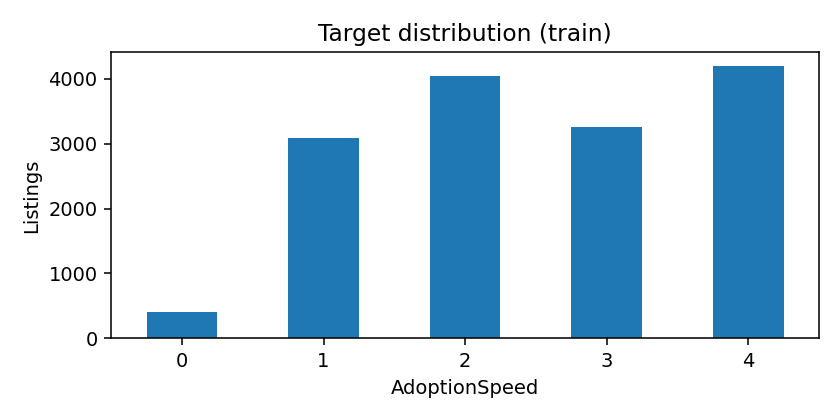

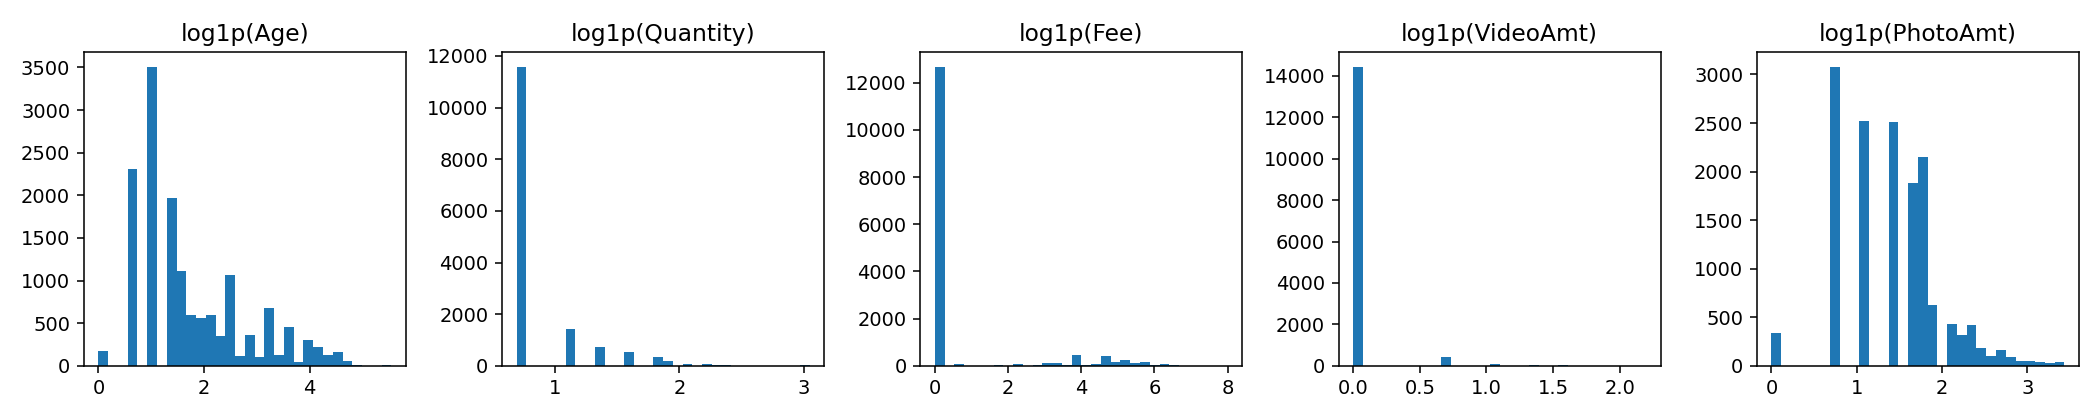

In [4]:
display(audit)
display(pd.read_csv(WORK_DIR / "eda/numeric_summary.csv", index_col=0))
display(Image(filename=str(WORK_DIR / "eda/class_distribution.png")))
display(Image(filename=str(WORK_DIR / "eda/numeric_distributions.png")))
train, test = load_data(DATA_ROOT)

## 2. Осмотр дополнительных модальностей

Ниже — несколько изображений и структура одного JSON каждого типа. Это осмотр
формата (не использую пока эти данных в модели). Покрытие всех объявлений и
ошибки декодирования выборки JSON находятся в audit.json.


images {'available': True, 'folder': '/kaggle/input/competitions/petfinder-adoption-prediction/train_images', 'files': 58311, 'rows_with_files': 14652, 'rows_without_files': 341, 'files_for_unknown_pet_ids': 0, 'rows_with_photo_count_mismatch': 0}


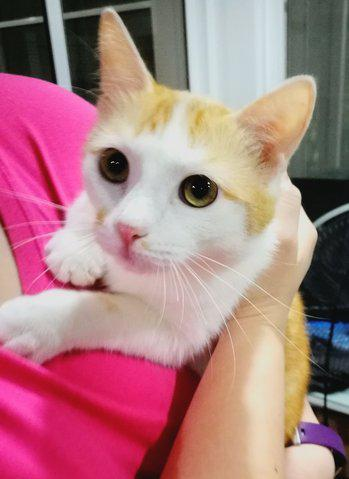

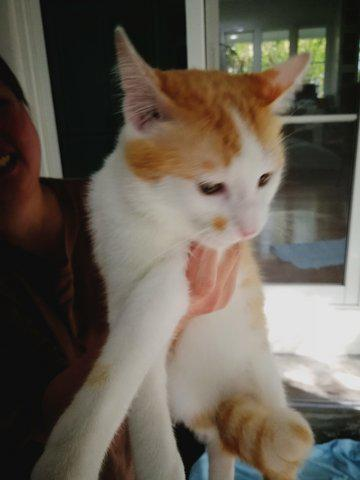

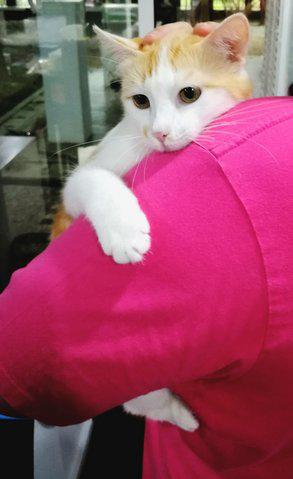

metadata {'available': True, 'folder': '/kaggle/input/competitions/petfinder-adoption-prediction/train_metadata', 'files': 58311, 'rows_with_files': 14652, 'rows_without_files': 341, 'files_for_unknown_pet_ids': 0, 'json_files_sampled': 100, 'sample_parse_failures': [], 'sampled_top_level_keys': ['cropHintsAnnotation', 'faceAnnotations', 'imagePropertiesAnnotation', 'labelAnnotations', 'textAnnotations']}
0008c5398-1.json top-level keys: ['labelAnnotations', 'imagePropertiesAnnotation', 'cropHintsAnnotation']
sentiment {'available': True, 'folder': '/kaggle/input/competitions/petfinder-adoption-prediction/train_sentiment', 'files': 14442, 'rows_with_files': 14442, 'rows_without_files': 551, 'files_for_unknown_pet_ids': 0, 'json_files_sampled': 100, 'sample_parse_failures': [], 'sampled_top_level_keys': ['categories', 'documentSentiment', 'entities', 'language', 'sentences', 'tokens']}
0008c5398.json top-level keys: ['sentences', 'tokens', 'entities', 'documentSentiment', 'language', 'c

In [5]:
for modality, info in audit.get("train_modalities", {}).items():
    print(modality, info)
    if not info.get("available"):
        continue
    folder = Path(info["folder"])
    if modality == "images":
        for path in sorted(folder.rglob("*.jpg"))[:3]:
            try:
                display(Image(filename=str(path), width=240))
            except (OSError, ValueError) as error:
                print(path.name, type(error).__name__)
    else:
        example = next(iter(sorted(folder.rglob("*.json"))), None)
        if example is not None:
            try:
                data = json.loads(example.read_text(encoding="utf-8"))
                print(example.name, "top-level keys:", list(data) if isinstance(data, dict) else type(data).__name__)
            except (OSError, ValueError) as error:
                print(example.name, type(error).__name__)

## 3. Локальная валидация и модели

5-fold StratifiedGroupKFold по RescuerID, seed=42.
Оцениваю перенос на новых авторов. Случайный stratified CV — отдельная диагностика для сценария со знакомыми авторами; сравнивать числа как один и тот же протокол нельзя.

Все imputer/scaler/OHE/TF-IDF обучаются внутри train-фолда. PetID, RescuerID,
Name не входят в X. Внешний val не участвует в early stopping или подборе порогов.

У регрессии фиксированные границы [0.5, 1.5, 2.5, 3.5]. Test не участвует в выборе.
Дубликаты текста между авторами остаются риском и считаются по каждому фолду.

Модели: most-frequent Dummy; Logistic Regression по таблице; та же модель с TF-IDF; CatBoostRegressor RMSE и CatBoostClassifier MultiClass по таблице.

In [6]:
RUN_DIR = WORK_DIR / "experiments"
summary = run_cv(train, CONFIG, RUN_DIR)
display(summary)
display(pd.read_csv(RUN_DIR / "fold_metrics.csv"))
display(json.loads((RUN_DIR / "split_diagnostics.json").read_text()))

dummy fold=0 QWK=0.0
dummy fold=1 QWK=0.0
dummy fold=2 QWK=0.0
dummy fold=3 QWK=0.0
dummy fold=4 QWK=0.0
logreg_tabular fold=0 QWK=0.2755896653390576
logreg_tabular fold=1 QWK=0.2709572100165424
logreg_tabular fold=2 QWK=0.2563319446261111
logreg_tabular fold=3 QWK=0.2683333842381903
logreg_tabular fold=4 QWK=0.22578633822341254
logreg_text fold=0 QWK=0.26645462818469745
logreg_text fold=1 QWK=0.2623280875028736
logreg_text fold=2 QWK=0.28210685201513186
logreg_text fold=3 QWK=0.28089623804539554
logreg_text fold=4 QWK=0.2423872706561635
catboost_regressor fold=0 QWK=0.25790017014622557
catboost_regressor fold=1 QWK=0.2592513544662671
catboost_regressor fold=2 QWK=0.26725143808079865
catboost_regressor fold=3 QWK=0.26000350014246854
catboost_regressor fold=4 QWK=0.2352800311312
catboost_classifier fold=0 QWK=0.34094313624764727
catboost_classifier fold=1 QWK=0.33357971686517207
catboost_classifier fold=2 QWK=0.3432728360943791
catboost_classifier fold=3 QWK=0.3380204784425833
catboost_

,model,qwk_mean,qwk_std,oof_qwk,oof_macro_f1,oof_accuracy,oof_mae,oof_recall_class_0,oof_severe_error_rate,seconds
4,catboost_classifier,0.329912,0.020539,0.329782,0.286963,0.389782,0.967185,0.000000,0.268459,420.042253
2,logreg_text,0.266835,0.016195,0.266503,0.275560,0.359835,1.036750,0.002439,0.296138,197.759637
1,logreg_tabular,0.259400,0.020092,0.259045,0.267821,0.355366,1.042420,0.004878,0.301141,11.456564
3,catboost_regressor,0.255937,0.012105,0.256175,0.166034,0.283132,0.888215,0.000000,0.161809,43.875933
0,dummy,0.000000,0.000000,-0.007848,0.118782,0.266191,1.424331,0.000000,0.477890,0.068141


,model,fold,qwk,macro_f1,accuracy,mae,recall_class_0,severe_error_rate,seconds
0,dummy,0,0.000000,0.086739,0.276889,1.460960,0.000000,0.488868,0.019127
1,dummy,1,0.000000,0.082353,0.259259,1.491259,0.000000,0.498963,0.012172
2,dummy,2,0.000000,0.091908,0.298315,1.481893,0.000000,0.504840,0.012231
3,dummy,3,0.000000,0.077204,0.239172,1.106554,0.000000,0.345726,0.011965
4,dummy,4,0.000000,0.081618,0.256351,1.531838,0.000000,0.531838,0.012645
5,logreg_tabular,0,0.275590,0.269682,0.347131,1.032299,0.010989,0.290687,2.180681
6,logreg_tabular,1,0.270957,0.277378,0.369481,1.013037,0.009901,0.289778,2.066113
7,logreg_tabular,2,0.256332,0.264444,0.354966,1.046612,0.000000,0.301542,2.399517
8,logreg_tabular,3,0.268333,0.267205,0.363358,1.037562,0.000000,0.303565,2.511637
9,logreg_tabular,4,0.225786,0.256670,0.341801,1.086110,0.000000,0.322336,2.298616


[{'fold': 0,
  'train_rows': 11804,
  'val_rows': 3189,
  'overlapping_rescuers': 0,
  'val_rows_with_train_description': 24,
  'train_class_counts': {'0': 319, '1': 2478, '2': 3181, '3': 2512, '4': 3314},
  'val_class_counts': {'0': 91, '1': 612, '2': 856, '3': 747, '4': 883}},
 {'fold': 1,
  'train_rows': 11618,
  'val_rows': 3375,
  'overlapping_rescuers': 0,
  'val_rows_with_train_description': 44,
  'train_class_counts': {'0': 309, '1': 2443, '2': 3101, '3': 2443, '4': 3322},
  'val_class_counts': {'0': 101, '1': 647, '2': 936, '3': 816, '4': 875}},
 {'fold': 2,
  'train_rows': 12204,
  'val_rows': 2789,
  'overlapping_rescuers': 0,
  'val_rows_with_train_description': 30,
  'train_class_counts': {'0': 332, '1': 2478, '2': 3319, '3': 2710, '4': 3365},
  'val_class_counts': {'0': 78, '1': 612, '2': 718, '3': 549, '4': 832}},
 {'fold': 3,
  'train_rows': 12384,
  'val_rows': 2609,
  'overlapping_rescuers': 0,
  'val_rows_with_train_description': 38,
  'train_class_counts': {'0': 338

## 4. Парное сравнение гипотезы о тексте

Bootstrap пересэмплирует целых авторов. Интервал относится к разнице pooled OOF
QWK двух уже обученных наборов моделей; он не учитывает полную вариативность
переобучения. Фолды пересекаются по обучающим данным, поэтому fold std не является доверительным интервалом. (TODO: отдельный untouched holdout или nested CV для менее смещенной итоговой оценки (?))

In [7]:
if {"logreg_tabular", "logreg_text"}.issubset(set(summary.model)):
    text_oof = pd.read_csv(RUN_DIR / "logreg_text/oof.csv")
    tab_oof = pd.read_csv(RUN_DIR / "logreg_tabular/oof.csv")
    paired = text_oof.merge(tab_oof[["PetID", "fold", "y_true", "prediction"]],
                            on=["PetID", "fold", "y_true"],
                            suffixes=("", "_tab"), validate="one_to_one")
    assert len(paired) == len(train)
    interval = group_bootstrap(paired, repeats=500, seed=CONFIG["seed"], other="prediction_tab")
    delta = float(summary.set_index("model").loc["logreg_text", "oof_qwk"] -
                  summary.set_index("model").loc["logreg_tabular", "oof_qwk"])
    result = {"delta_oof_qwk_text_minus_tabular": delta, "paired_group_bootstrap": interval}
    (RUN_DIR / "text_hypothesis.json").write_text(json.dumps(result, indent=2))
    display(result)

{'delta_oof_qwk_text_minus_tabular': 0.007458070209062639,
 'paired_group_bootstrap': {'low': -0.009094138417905925,
  'high': 0.026049724555007227,
  'valid_repeats': 500,
  'requested_repeats': 500}}

## 5. Ошибки и отчет

# Локальная валидация

Метрики рассчитаны по сохраненным OOF-предсказаниям.

| model | qwk_mean | qwk_std | oof_macro_f1 | oof_mae |
| --- | --- | --- | --- | --- |
| catboost_classifier | 0.3299 | 0.0205 | 0.287 | 0.9672 |
| logreg_text | 0.2668 | 0.0162 | 0.2756 | 1.0368 |
| logreg_tabular | 0.2594 | 0.0201 | 0.2678 | 1.0424 |
| catboost_regressor | 0.2559 | 0.0121 | 0.166 | 0.8882 |
| dummy | 0.0 | 0.0 | 0.1188 | 1.4243 |

Среднее и std относятся к фолдам; это не независимые запуски. Pooled OOF QWK в summary.csv отличается от среднего по фолдам.

![Сравнение моделей](model_comparison.png)


## catboost_classifier

![Матрица ошибок](catboost_classifier/confusion_matrix.png)

Три наибольшие ошибки (это примеры, не доказательство систематического паттерна):

| PetID | Type | Age | y_true | prediction | absolute_error |
| --- | --- | --- | --- | --- | --- |
| b0c918c91 | 2 | 6 | 0 | 4 | 4 |
| 142da3f69 | 2 | 7 | 0 | 4 | 4 |
| 6097a5c1d | 1 | 2 | 0 | 4 | 4 |

## logreg_text

![Матрица ошибок](logreg_text/confusion_matrix.png)

Три наибольшие ошибки (это примеры, не доказательство систематического паттерна):

| PetID | Type | Age | y_true | prediction | absolute_error |
| --- | --- | --- | --- | --- | --- |
| 1a8fd6707 | 2 | 12 | 0 | 4 | 4 |
| 98da79d01 | 1 | 1 | 0 | 4 | 4 |
| f78698cc4 | 1 | 60 | 0 | 4 | 4 |

## logreg_tabular

![Матрица ошибок](logreg_tabular/confusion_matrix.png)

Три наибольшие ошибки (это примеры, не доказательство систематического паттерна):

| PetID | Type | Age | y_true | prediction | absolute_error |
| --- | --- | --- | --- | --- | --- |
| 624b5493f | 2 | 3 | 0 | 4 | 4 |
| 80b137b2a | 1 | 3 | 0 | 4 | 4 |
| 6607c6e22 | 2 | 8 | 0 | 4 | 4 |

## catboost_regressor

![Матрица ошибок](catboost_regressor/confusion_matrix.png)

Три наибольшие ошибки (это примеры, не доказательство систематического паттерна):

| PetID | Type | Age | y_true | prediction | absolute_error |
| --- | --- | --- | --- | --- | --- |
| dcd70e1e3 | 1 | 11 | 0 | 4 | 4 |
| 72418da1c | 1 | 1 | 0 | 4 | 4 |
| bd18b6cf6 | 2 | 12 | 0 | 3 | 3 |

## dummy

![Матрица ошибок](dummy/confusion_matrix.png)

Три наибольшие ошибки (это примеры, не доказательство систематического паттерна):

| PetID | Type | Age | y_true | prediction | absolute_error |
| --- | --- | --- | --- | --- | --- |
| 383e5b82e | 1 | 72 | 0 | 4 | 4 |
| 172305d1b | 1 | 2 | 0 | 4 | 4 |
| c4718084c | 2 | 2 | 0 | 4 | 4 |

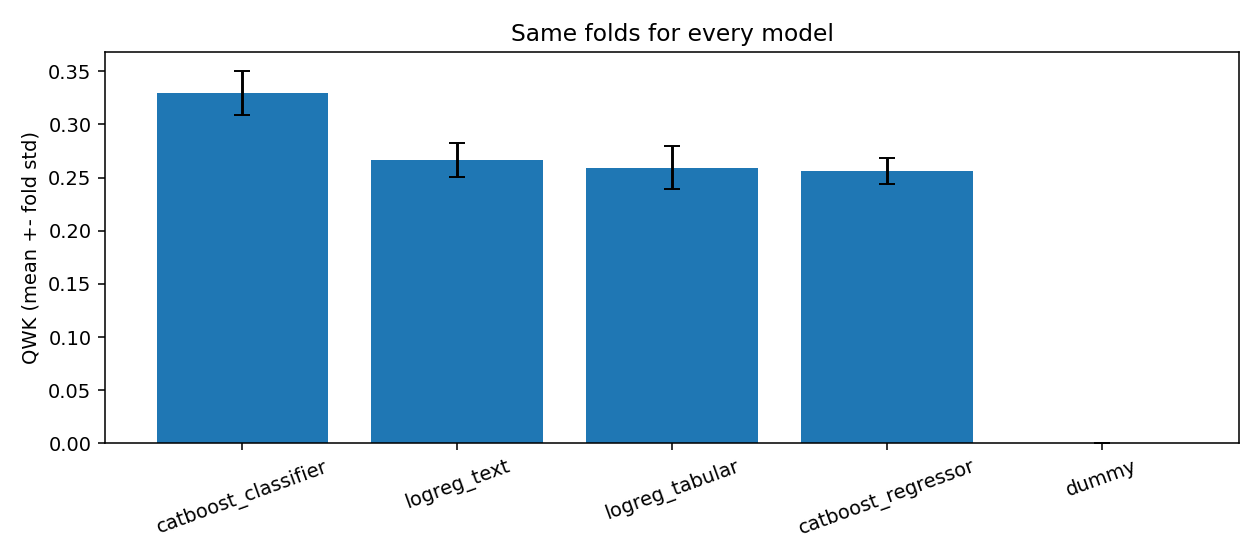

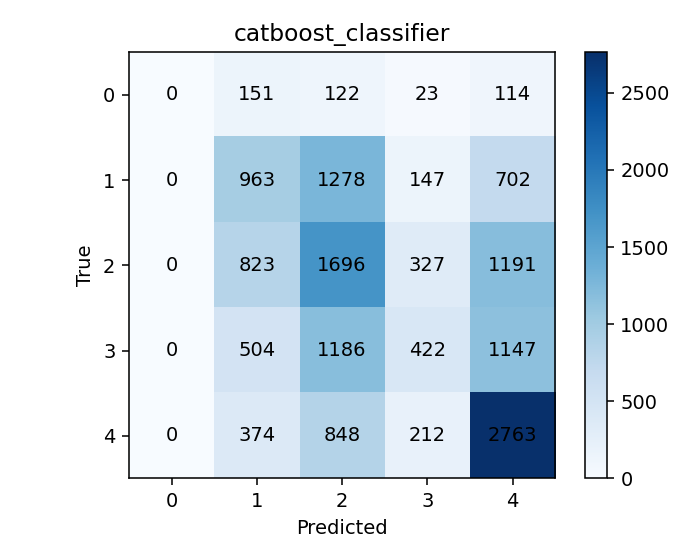

,PetID,RescuerID,Type,Age,Quantity,PhotoAmt,fold,y_true,prediction,absolute_error
0,b0c918c91,28e4610089584f9396900d60be899a0e,2,6,1,0.0,1,0,4,4
1,142da3f69,cdf2cd8d67e53bf6e5088dcb2de317d6,2,7,1,4.0,2,0,4,4
2,6097a5c1d,fa90fa5b1ee11c86938398b60abc32cb,1,2,1,0.0,1,0,4,4


,column,value,n,qwk,macro_f1,accuracy,mae,recall_class_0,severe_error_rate
0,Type,1.0,8132,0.330718,0.286811,0.400271,0.921667,0.0,0.252459
1,Type,2.0,6861,0.310372,0.273643,0.377350,1.021134,0.0,0.287422
2,Quantity,1.0,11565,0.334999,0.288820,0.386770,0.963251,0.0,0.263208
3,Quantity,2.0,1422,0.322795,0.287229,0.390999,0.985935,0.0,0.289030
4,Quantity,3.0,726,0.328328,0.272115,0.382920,0.987603,0.0,0.271350
5,Quantity,4.0,531,0.302232,0.275022,0.431262,0.962335,0.0,0.280603
6,Quantity,5.0,333,0.207716,0.255933,0.414414,0.981982,0.0,0.306306
7,Quantity,6.0,185,0.228891,0.229863,0.410811,0.962162,0.0,0.286486
8,Quantity,7.0,84,0.269373,0.286097,0.440476,0.857143,0.0,0.238095
9,Quantity,8.0,52,0.004289,0.239521,0.346154,1.134615,0.0,0.365385


In [8]:
report_path = build_report(RUN_DIR)
display(Markdown(report_path.read_text()))
display(Image(filename=str(RUN_DIR / "model_comparison.png")))
best_model = summary.iloc[0]["model"]  # По mean fold QWK, только local validation.
display(Image(filename=str(RUN_DIR / best_model / "confusion_matrix.png")))
display(pd.read_csv(RUN_DIR / best_model / "errors.csv").head(3))
slice_path = RUN_DIR / best_model / "slices.csv"
if slice_path.stat().st_size > 1:
    display(pd.read_csv(slice_path))

## 6. Full-data refit и submission

Выбранная на CV модель обучается на всем train, предсказывает test и сохраняется вместе с submission.csv.

In [9]:
if RUN_REFIT:
    sample_candidates = [DATA_ROOT / "sample_submission.csv", DATA_ROOT / "test/sample_submission.csv"]
    sample_path = next((p for p in sample_candidates if p.is_file()), None)
    submission = fit_submission(train, test, CONFIG, best_model, WORK_DIR / "refit", sample_path)
    display(submission.head())
    print("Submission:", WORK_DIR / "refit/submission.csv")
import shutil
archive_path = shutil.make_archive(str(WORK_DIR.parent / "petfinder_artifacts"), "zip", WORK_DIR)
print("Download artifacts:", archive_path)

,PetID,AdoptionSpeed
0,e2dfc2935,4
1,f153b465f,1
2,3c90f3f54,1
3,e02abc8a3,4
4,09f0df7d1,4


Submission: /kaggle/working/petfinder_outputs/refit/submission.csv
Download artifacts: /kaggle/working/petfinder_artifacts.zip


In [ ]:
for_submit = pd.read_csv("/kaggle/working/petfinder_outputs/refit/submission.csv")
submission = for_submit.copy()
submission.to_csv("submission.csv", index=False)